# Week 4 · Notebook 1 - Forgetting curves and rule-based schedulers

Before we let an agent learn *when* to quiz, we need (1) a model of forgetting to simulate students and (2) a hand-made baseline to beat.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))   # so we can import the remind package
import random
import matplotlib.pyplot as plt
from remind.memory_model import SimulatedStudent, recall_probability, retention_area

## 1. The forgetting curve
$$P(\text{recall after } t \text{ days}) = 0.9^{\,t/S}$$
**Stability** $S$ = days until recall drops to 90%. Large $S$ → slow forgetting. A good review makes $S$ jump; a failed one shrinks it.

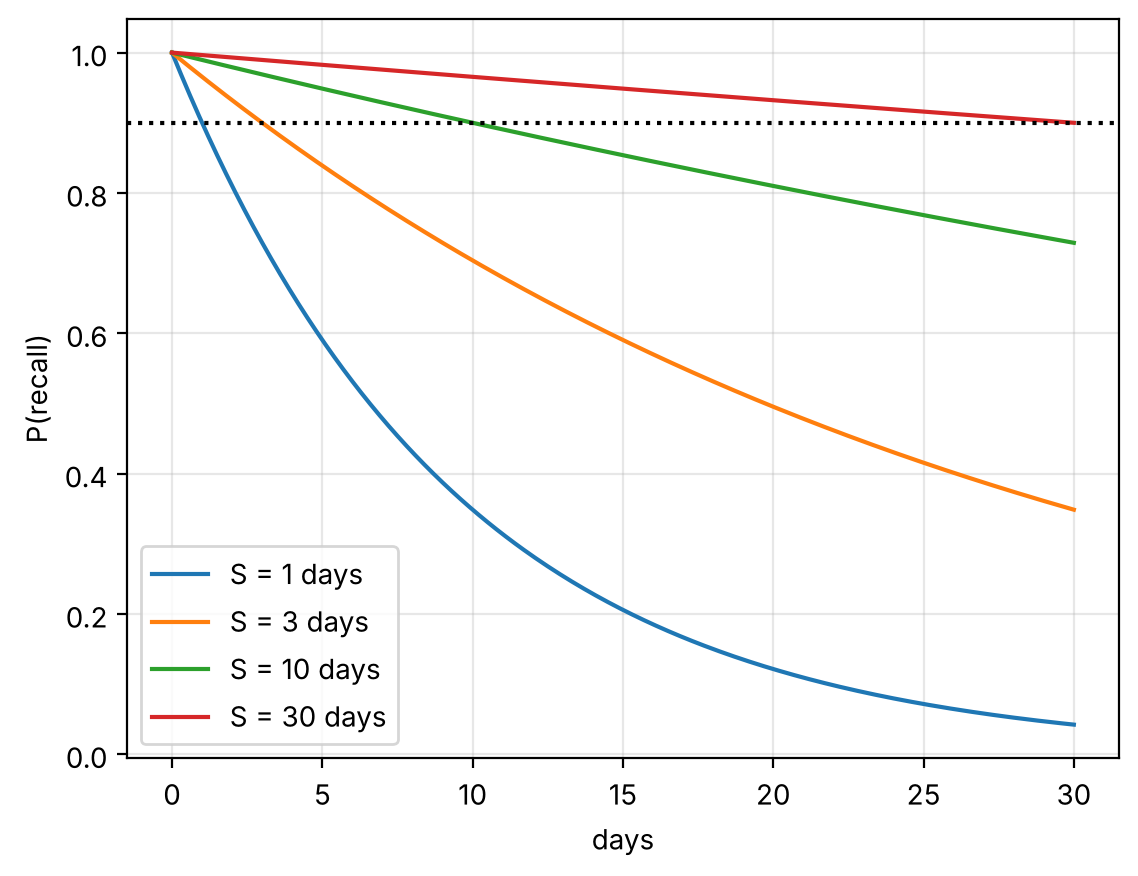

In [2]:
ts = [d / 10 for d in range(301)]
for S in [1, 3, 10, 30]:
    plt.plot(ts, [recall_probability(t, S) for t in ts], label=f'S = {S} days')
plt.axhline(0.9, ls=':', c='k'); plt.xlabel('days'); plt.ylabel('P(recall)'); plt.legend(); plt.grid(alpha=.3); plt.show()

## 2. A simulated student
Read `remind/memory_model.py`. Key rules:
* successful recall: $S \leftarrow S \cdot \big(1 + (2 - 1.8d)(1 + 2(1-p))\big)$ - **harder recalls (low $p$) grow memory more** (desirable difficulty).
* failure: $S \leftarrow 0.5\,S$.
* the student reports *easy* / *hard* / *forgot* - exactly the 3 grades Gemini will give in Week 5.
* difficulty $d$ is **hidden** from the scheduler.

In [3]:
student = SimulatedStudent(difficulty=0.3, rng=random.Random(1))
for gap in [1, 2, 4, 7, 14]:
    grade, p = student.review(gap)
    print(f'waited {gap:2d} d  p={p:.2f}  grade={grade}  new S={student.stability:5.1f} d')

waited  1 d  p=0.91  grade=2  new S=  3.1 d
waited  2 d  p=0.93  grade=2  new S=  8.2 d
waited  4 d  p=0.95  grade=2  new S= 21.4 d
waited  7 d  p=0.97  grade=2  new S= 54.8 d
waited 14 d  p=0.97  grade=1  new S=139.0 d


## 3. Leitner boxes (last year's 'level' idea)
Level = number of correct answers in a row. Each level has a fixed gap: **1, 2, 4, 7, 14, 30 days**. Wrong answer → back to level 0.

In [4]:
from remind.env import SpacedRepetitionEnv, GAPS
from remind.schedulers import leitner, fixed, evaluate
make_env = lambda seed: SpacedRepetitionEnv(seed=seed)
for name, pol in [('every day', fixed(1)), ('every 4 days', fixed(4)), ('every week', fixed(7)), ('Leitner', leitner)]:
    m = evaluate(pol, make_env, n=1000)
    print(f"{name:13s} reviews {m['reviews']:5.1f}   retention {m['retention']:.1%}   exam pass {m['exam_pass']:.1%}")

every day     reviews  60.0   retention 99.5%   exam pass 100.0%
every 4 days  reviews  15.0   retention 83.2%   exam pass 81.7%
every week    reviews   9.0   retention 61.5%   exam pass 54.6%
Leitner       reviews   9.9   retention 93.4%   exam pass 95.1%


**Retention** = average recall probability over the 60 days. **Exam pass** = recalled on day 60.

Leitner is a strong baseline. But the same ladder for an easy and a hard item? Let's look.

In [5]:
for d in [0.1, 0.5, 0.9]:
    env = SpacedRepetitionEnv(seed=0)
    tot = {'reviews': 0, 'retention': 0}
    for _ in range(500):
        env.reset(difficulty=d); done = False
        while not done:
            _, _, done, _ = env.step(leitner(env.streak, env.grade))
        for k in tot: tot[k] += env.metrics()[k] / 500
    print(f"difficulty {d}: reviews {tot['reviews']:4.1f}, retention {tot['retention']:.1%}")

difficulty 0.1: reviews  7.3, retention 99.2%
difficulty 0.5: reviews  7.9, retention 97.1%
difficulty 0.9: reviews 15.8, retention 81.3%


## ✍️ Exercises
1. Design your **own** rule-based scheduler using the easy/hard grade (e.g. skip a level on *easy*). Does it beat Leitner? (Hint: `schedulers.leitner_plus` is one try - it doesn't!)
2. Plot one hard item's recall probability over 60 days under Leitner. Where does it fail?
3. Why can't a fixed rule be optimal for every student? Write 3-4 lines.